# Python for Data Science — Practice Notebook

| # | Topic |
|---|-------|
| 1 | Control Flow and Functions |
| 2 | Data Structures and File Handling |
| 3 | Object-Oriented Programming |
| 4 | Data Science Libraries (NumPy, Pandas, Matplotlib, Seaborn) |
| 5 | Introduction to Machine Learning (scikit-learn) |
| 6 | Debugging and Code Optimization (incl. Git/GitHub) |


# Topic 1 · Control Flow and Functions
Control flow decides **which** lines of code run and **how often**. Functions package logic so it can be reused and tested.

## 1.1 Conditional statements (if / elif / else, nested conditions)
A conditional lets a program make decisions. Python checks conditions top to bottom and runs the **first** block whose condition is `True`.

* `if` – the first test
* `elif` – further tests (only checked if earlier ones failed)
* `else` – the fallback
* **Nested** conditions put one `if` inside another when a second decision depends on the first.

**Data-science use:** categorising values (e.g. grading scores, flagging outliers, labelling risk levels).

In [1]:
def grade(score):
    """Return a letter grade for a score between 0 and 100."""
    if score < 0 or score > 100:
        return "Invalid score"
    elif score >= 80:
        return "A"
    elif score >= 70:
        return "B"
    elif score >= 60:
        return "C"
    elif score >= 50:
        return "D"
    else:
        return "F"

for s in [95, 72, 55, 30, 120]:
    print(f"Score {s:>3} -> {grade(s)}")

# Nested condition: a loan decision that depends on two checks
def loan_decision(income, credit_score):
    if income >= 1_000_000:                # UGX per month
        if credit_score >= 650:
            return "Approved"
        else:
            return "Manual review (low credit score)"
    else:
        return "Declined (income too low)"

print(loan_decision(1_500_000, 700))
print(loan_decision(1_500_000, 500))
print(loan_decision(400_000, 800))

Score  95 -> A
Score  72 -> B
Score  55 -> D
Score  30 -> F
Score 120 -> Invalid score
Approved
Manual review (low credit score)
Declined (income too low)


## 1.2 Loops and iteration (`for`, `while`)
* **`for`** iterates over a known sequence (list, range, string, dictionary...).
* **`while`** repeats **as long as** a condition stays true — use it when you don't know in advance how many repeats you need.
* `break` exits a loop early, `continue` skips to the next iteration.
* `enumerate()` gives index + value; `zip()` walks two sequences together.

In [2]:
# for loop: compute the average of a list
marks = [68, 74, 81, 59, 90]
total = 0
for m in marks:
    total += m
print("Average:", total / len(marks))

# enumerate and zip
students = ["Aisha", "Brian", "Cynthia"]
scores   = [88, 67, 92]
for i, (name, score) in enumerate(zip(students, scores), start=1):
    print(f"{i}. {name}: {score}")

# while loop: how many years for savings to double at 8% interest?
balance, years = 1000, 0
while balance < 2000:
    balance *= 1.08
    years += 1
print(f"Doubled after {years} years (balance = {balance:.2f})")

# break / continue
for n in range(1, 11):
    if n % 2 == 0:
        continue          # skip even numbers
    if n > 7:
        break             # stop once n passes 7
    print("odd:", n)

# List comprehension: a compact for loop
squares = [n**2 for n in range(1, 8)]
print(squares)

Average: 74.4
1. Aisha: 88
2. Brian: 67
3. Cynthia: 92
Doubled after 10 years (balance = 2158.92)
odd: 1
odd: 3
odd: 5
odd: 7
[1, 4, 9, 16, 25, 36, 49]


## 1.3 Functions and modular programming
A **function** is a named, reusable block of code. Good functions:

* do **one** job,
* take **parameters** and `return` a result (rather than printing),
* have **docstrings** and sensible **default** values.

Splitting a program into small functions is **modular programming** — each piece can be tested and reused independently.

In [3]:
def summarise(values, round_to=2):
    """Return mean, min and max of a list of numbers."""
    mean = sum(values) / len(values)
    return {
        "mean": round(mean, round_to),
        "min": min(values),
        "max": max(values),
    }

print(summarise([12, 15, 11, 19, 14]))

# *args and **kwargs - flexible numbers of arguments
def describe(*numbers, **options):
    result = sum(numbers)
    if options.get("square"):
        result **= 2
    return result

print(describe(1, 2, 3))
print(describe(1, 2, 3, square=True))

# Modular design: small functions combined into a pipeline
def clean(values):
    return [v for v in values if v is not None]

def normalise(values):
    lo, hi = min(values), max(values)
    return [(v - lo) / (hi - lo) for v in values]

raw = [10, None, 20, 30, None, 50]
print(normalise(clean(raw)))

{'mean': 14.2, 'min': 11, 'max': 19}
6
36
[0.0, 0.25, 0.5, 1.0]


## 1.4 Recursion and lambda functions
* **Recursion**: a function that calls **itself** on a smaller version of the problem. It needs a **base case** (when to stop) and a **recursive case**.
* **Lambda**: a small anonymous one-line function, handy with `map`, `filter`, `sorted` and pandas `.apply()`.

In [4]:
def factorial(n):
    if n <= 1:            # base case
        return 1
    return n * factorial(n - 1)   # recursive case

print("5! =", factorial(5))

def fibonacci(n):
    if n < 2:
        return n
    return fibonacci(n - 1) + fibonacci(n - 2)

print([fibonacci(i) for i in range(10)])

# Lambda functions
square = lambda x: x ** 2
print(square(9))

people = [("Aisha", 21), ("Brian", 19), ("Cynthia", 23)]
print(sorted(people, key=lambda p: p[1]))               # sort by age
print(list(map(lambda x: x * 1.18, [100, 200, 300])))   # add 18% VAT
print(list(filter(lambda x: x > 50, [10, 60, 30, 80]))) # keep values > 50

5! = 120
[0, 1, 1, 2, 3, 5, 8, 13, 21, 34]
81
[('Brian', 19), ('Aisha', 21), ('Cynthia', 23)]
[118.0, 236.0, 354.0]
[60, 80]


### Practice — Topic 1
1. Write `is_prime(n)` using a loop and an `if` statement.
2. Write a recursive `sum_digits(n)` (e.g. `sum_digits(1234) = 10`).
3. Use a lambda with `sorted` to order words by length.

In [5]:
# --- Your practice area; sample solutions below ---
def is_prime(n):
    if n < 2:
        return False
    for i in range(2, int(n ** 0.5) + 1):
        if n % i == 0:
            return False
    return True

def sum_digits(n):
    return n if n < 10 else (n % 10) + sum_digits(n // 10)

print([n for n in range(1, 30) if is_prime(n)])
print(sum_digits(1234))
print(sorted(["python", "is", "fun", "pandas"], key=lambda w: len(w)))

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29]
10
['is', 'fun', 'python', 'pandas']


# Topic 2 · Data Structures and File Handling
Choosing the right container for your data makes code simpler and faster. Files let your data outlive the program, and exception handling stops errors from crashing it.

## 2.1 Lists, tuples, sets and dictionaries
| Structure | Syntax | Ordered | Mutable | Duplicates | Typical use |
|-----------|--------|:------:|:------:|:---------:|-------------|
| **List** | `[1, 2, 3]` | ✅ | ✅ | allowed | a collection that changes (a column of values) |
| **Tuple** | `(1, 2, 3)` | ✅ | ❌ | allowed | fixed records (coordinates, a row) |
| **Set** | `{1, 2, 3}` | ❌ | ✅ | **removed** | unique items, membership tests, set maths |
| **Dictionary** | `{"a": 1}` | ✅ (insertion) | ✅ | unique keys | labelled data (key → value lookup) |

In [4]:
# LIST - ordered, changeable
fruits = ["mango", "banana", "pawpaw"]
fruits.append("pineapple")
fruits[1] = "passion fruit"
print(fruits, "| first:", fruits[0], "| last two:", fruits[-2:])

# TUPLE - ordered, unchangeable
location = (0.3476, 32.5825)      # Kampala (lat, lon)
lat, lon = location               # unpacking
print("lat:", lat, "lon:", lon)

# SET - unique values and set operations
a = {1, 2, 3, 4}
b = {3, 4, 5, 6}
print("union:", a | b, "| intersection:", a & b, "| difference:", a - b)
print("Unique tags:", set(["python", "sql", "python", "excel", "sql"]))

# DICTIONARY - key/value pairs
student = {"name": "Salma", "year": 4, "courses": ["Statistics", "BPM"]}
student["gpa"] = 4.2
print(student["name"], student.get("grade", "not set"))
for key, value in student.items():
    print(f"  {key}: {value}")

# Counting with a dictionary (word frequency)
text = "data science is fun and data is everywhere"
counts = {}
for word in text.split():
    counts[word] = counts.get(word, 0) + 1
print(counts)

# Nested structure: list of dictionaries = a mini table
records = [
    {"name": "Aisha", "score": 88},
    {"name": "Brian", "score": 67},
]
print([r["name"] for r in records if r["score"] > 70])

['mango', 'passion fruit', 'pawpaw', 'pineapple'] | first: mango | last two: ['pawpaw', 'pineapple']
lat: 0.3476 lon: 32.5825
union: {1, 2, 3, 4, 5, 6} | intersection: {3, 4} | difference: {1, 2}
Unique tags: {'excel', 'sql', 'python'}
Salma not set
  name: Salma
  year: 4
  courses: ['Statistics', 'BPM']
  gpa: 4.2
{'data': 2, 'science': 1, 'is': 2, 'fun': 1, 'and': 1, 'everywhere': 1}
['Aisha']


## 2.2 File input and output
Use `open()` inside a **`with`** block — Python closes the file automatically, even if something goes wrong.

| Mode | Meaning |
|------|---------|
| `"r"` | read (default) |
| `"w"` | write (overwrites!) |
| `"a"` | append to the end |

For tabular data use the `csv` module (or pandas later); for structured data use `json`.

In [5]:
import csv, json, os

os.makedirs("practice_files", exist_ok=True)

# --- Write and read a text file ---
with open("practice_files/notes.txt", "w") as f:
    f.write("Python for Data Science\n")
    f.write("File handling practice\n")

with open("practice_files/notes.txt", "a") as f:        # append
    f.write("Appended line\n")

with open("practice_files/notes.txt", "r") as f:
    for line_no, line in enumerate(f, start=1):
        print(line_no, line.strip())

# --- CSV ---
rows = [["name", "score"], ["Aisha", 88], ["Brian", 67], ["Cynthia", 92]]
with open("practice_files/scores.csv", "w", newline="") as f:
    csv.writer(f).writerows(rows)

with open("practice_files/scores.csv") as f:
    for row in csv.DictReader(f):
        print(row["name"], "->", row["score"])

# --- JSON ---
data = {"course": "Python", "topics": [1, 2, 3, 4, 5, 6]}
with open("practice_files/data.json", "w") as f:
    json.dump(data, f, indent=2)
with open("practice_files/data.json") as f:
    print(json.load(f))

1 Python for Data Science
2 File handling practice
3 Appended line
Aisha -> 88
Brian -> 67
Cynthia -> 92
{'course': 'Python', 'topics': [1, 2, 3, 4, 5, 6]}


## 2.3 Exception handling
Errors at run time are called **exceptions**. `try / except` lets you handle them gracefully:

```
try:      risky code
except X: what to do if error X occurs
else:     runs only if there was NO error
finally:  ALWAYS runs (clean-up)
```
You can also `raise` your own exceptions to enforce rules.

In [6]:
def safe_divide(a, b):
    try:
        result = a / b
    except ZeroDivisionError:
        print("Cannot divide by zero")
        return None
    except TypeError:
        print("Both inputs must be numbers")
        return None
    else:
        return result
    finally:
        print("-- division attempted --")

print(safe_divide(10, 2))
print(safe_divide(10, 0))
print(safe_divide(10, "a"))

# Handling a missing file
def read_file(path):
    try:
        with open(path) as f:
            return f.read()
    except FileNotFoundError:
        return f"'{path}' was not found."

print(read_file("does_not_exist.txt"))

# Raising our own exception
def set_age(age):
    if age < 0:
        raise ValueError("Age cannot be negative")
    return age

try:
    set_age(-5)
except ValueError as e:
    print("Caught:", e)

-- division attempted --
5.0
Cannot divide by zero
-- division attempted --
None
Both inputs must be numbers
-- division attempted --
None
'does_not_exist.txt' was not found.
Caught: Age cannot be negative


### Practice — Topic 2
1. Read `scores.csv` and compute the average score using a list.
2. Remove duplicates from a list while keeping the order.
3. Ask for a number and keep asking until the input is valid (`while` + `try/except`) — simulated below.

In [7]:
# 1. Average from CSV
with open("practice_files/scores.csv") as f:
    scores = [int(r["score"]) for r in csv.DictReader(f)]
print("Average:", sum(scores) / len(scores))

# 2. Remove duplicates, keep order
items = [3, 1, 3, 2, 1, 5]
print(list(dict.fromkeys(items)))

# 3. Input validation (simulated inputs so the notebook runs unattended)
attempts = iter(["abc", "", "42"])
while True:
    raw = next(attempts)
    try:
        number = int(raw)
        break
    except ValueError:
        print(f"'{raw}' is not a valid number, try again")
print("Accepted:", number)

Average: 82.33333333333333
[3, 1, 2, 5]
'abc' is not a valid number, try again
'' is not a valid number, try again
Accepted: 42


# Topic 3 · Object-Oriented Programming (OOP)
OOP models real-world things as **objects** that bundle **data (attributes)** and **behaviour (methods)**.

## 3.1 Classes and objects
* A **class** is a blueprint; an **object** (instance) is a thing built from it.
* `__init__` is the constructor — it runs when an object is created.
* `self` refers to the object itself.
* `__str__` controls how the object prints.

In [8]:
class Student:
    school = "Victoria University"            # class attribute (shared)

    def __init__(self, name, year):
        self.name = name                       # instance attributes
        self.year = year
        self.marks = []

    def add_mark(self, mark):
        self.marks.append(mark)

    def average(self):
        return sum(self.marks) / len(self.marks) if self.marks else 0

    def __str__(self):
        return f"{self.name} (Year {self.year}) - avg {self.average():.1f}"

s1 = Student("Aisha", 4)
s2 = Student("Brian", 3)
for m in (80, 90, 85):
    s1.add_mark(m)
s2.add_mark(60)

print(s1)
print(s2)
print(Student.school)

Aisha (Year 4) - avg 85.0
Brian (Year 3) - avg 60.0
Victoria University


## 3.2 Inheritance, encapsulation and polymorphism
* **Inheritance** – a *child* class reuses and extends a *parent* class (`class Child(Parent)`); `super()` calls the parent.
* **Encapsulation** – hide internal data and control access. A leading underscore (`_x`) means *protected by convention*; double underscore (`__x`) triggers name-mangling (*private*). Use methods/`@property` for controlled access.
* **Polymorphism** – different classes provide the **same method name** with different behaviour, so one piece of code can work with all of them.

In [9]:
# ---------- Inheritance + Encapsulation ----------
class BankAccount:
    def __init__(self, owner, balance=0):
        self.owner = owner
        self.__balance = balance               # private attribute

    @property
    def balance(self):                         # read-only access
        return self.__balance

    def deposit(self, amount):
        if amount <= 0:
            raise ValueError("Deposit must be positive")
        self.__balance += amount

    def withdraw(self, amount):
        if amount > self.__balance:
            raise ValueError("Insufficient funds")
        self.__balance -= amount

class SavingsAccount(BankAccount):             # inherits from BankAccount
    def __init__(self, owner, balance=0, rate=0.05):
        super().__init__(owner, balance)       # call the parent constructor
        self.rate = rate

    def add_interest(self):
        self.deposit(self.balance * self.rate)

acc = SavingsAccount("Salma", 1000)
acc.deposit(500)
acc.add_interest()
print("Balance:", acc.balance)

try:
    acc.balance = 1_000_000                    # blocked - property has no setter
except AttributeError as e:
    print("Encapsulation at work:", e)

# ---------- Polymorphism ----------
class Shape:
    def area(self):
        raise NotImplementedError

class Rectangle(Shape):
    def __init__(self, w, h): self.w, self.h = w, h
    def area(self): return self.w * self.h

class Circle(Shape):
    def __init__(self, r): self.r = r
    def area(self): return 3.14159 * self.r ** 2

for shape in [Rectangle(3, 4), Circle(2)]:     # same call, different behaviour
    print(type(shape).__name__, "area =", round(shape.area(), 2))

Balance: 1575.0
Encapsulation at work: property 'balance' of 'SavingsAccount' object has no setter
Rectangle area = 12
Circle area = 12.57


## 3.3 Working with Python modules and packages
* A **module** is any `.py` file; `import` brings its code into yours.
* A **package** is a folder of modules containing an `__init__.py` file.
* Import styles: `import math`, `from math import sqrt`, `import numpy as np`.
* Use `if __name__ == "__main__":` so code runs only when the file is executed directly, not when imported.

Below we **create our own module and package on disk**, then import them.

In [10]:
import math, random, statistics, datetime
print(math.sqrt(144), math.pi)
print(statistics.mean([2, 4, 6, 8]))
print(datetime.date.today())

# --- Build our own module ---
import os, sys
os.makedirs("my_package", exist_ok=True)

with open("my_package/__init__.py", "w") as f:
    f.write("from .stats_tools import mean, spread\n")

with open("my_package/stats_tools.py", "w") as f:
    f.write('''
def mean(values):
    return sum(values) / len(values)

def spread(values):
    return max(values) - min(values)

if __name__ == "__main__":
    print("Running stats_tools directly")
''')

sys.path.insert(0, os.getcwd())
import importlib, my_package
importlib.reload(my_package)
from my_package import mean, spread
print(mean([10, 20, 30]), spread([10, 20, 30]))

12.0 3.141592653589793
5
2026-10-06
20.0 20


### Practice — Topic 3
Create a `Vehicle` parent class and `Car` / `Motorcycle` children, each with a `describe()` method (polymorphism).

In [11]:
class Vehicle:
    def __init__(self, brand, wheels):
        self.brand, self.wheels = brand, wheels
    def describe(self):
        return f"{self.brand} with {self.wheels} wheels"

class Car(Vehicle):
    def __init__(self, brand):
        super().__init__(brand, 4)
    def describe(self):
        return "Car: " + super().describe()

class Motorcycle(Vehicle):
    def __init__(self, brand):
        super().__init__(brand, 2)
    def describe(self):
        return "Bike: " + super().describe()

for v in [Car("Toyota"), Motorcycle("Bajaj")]:
    print(v.describe())

Car: Toyota with 4 wheels
Bike: Bajaj with 2 wheels


---
# Topic 4 · Data Science Libraries in Python
The core stack: **NumPy** (fast numbers), **Pandas** (tables), **Matplotlib & Seaborn** (charts).

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
print("NumPy", np.__version__, "| Pandas", pd.__version__)

NumPy 2.3.5 | Pandas 2.3.3


## 4.1 NumPy — arrays and matrices
NumPy's **`ndarray`** stores numbers in a compact, typed block of memory, so maths is applied to **whole arrays at once** (*vectorisation*) — far faster than Python loops.

Key ideas: creating arrays, `shape`, indexing/slicing, boolean masks, **broadcasting**, aggregation (`mean`, `sum`, `axis=`), and matrix operations (`@`, `.T`, `np.linalg`).

In [13]:
a = np.array([1, 2, 3, 4, 5])
print("array:", a, "| shape:", a.shape, "| dtype:", a.dtype)

# Creating arrays
print(np.zeros((2, 3)))
print(np.arange(0, 10, 2), np.linspace(0, 1, 5))

# Vectorised operations (no loop!)
print(a * 2, a ** 2, a + np.array([10, 20, 30, 40, 50]))

# 2-D arrays (matrices)
M = np.array([[1, 2, 3],
              [4, 5, 6]])
print("M.shape:", M.shape, "| M[1, 2] =", M[1, 2], "| first column:", M[:, 0])
print("column means:", M.mean(axis=0), "| row sums:", M.sum(axis=1))

# Boolean masking
data = np.array([12, 45, 7, 33, 58, 21])
print(data[data > 20])

# Broadcasting: add a row vector to every row
print(M + np.array([100, 200, 300]))

# Matrix algebra
A = np.array([[2, 1], [1, 3]])
B = np.array([[1, 0], [4, 2]])
print("A @ B =\n", A @ B)
print("Transpose:\n", A.T)
print("Determinant:", round(np.linalg.det(A), 2))
print("Inverse:\n", np.linalg.inv(A))

# Solve the system  2x + y = 5 ;  x + 3y = 10
print("Solution [x, y]:", np.linalg.solve(A, np.array([5, 10])))

# Random data with a seed (reproducible)
rng = np.random.default_rng(42)
sample = rng.normal(loc=50, scale=10, size=1000)
print("sample mean ~", sample.mean().round(2), "| std ~", sample.std().round(2))

array: [1 2 3 4 5] | shape: (5,) | dtype: int64
[[0. 0. 0.]
 [0. 0. 0.]]
[0 2 4 6 8] [0.   0.25 0.5  0.75 1.  ]
[ 2  4  6  8 10] [ 1  4  9 16 25] [11 22 33 44 55]
M.shape: (2, 3) | M[1, 2] = 6 | first column: [1 4]
column means: [2.5 3.5 4.5] | row sums: [ 6 15]
[45 33 58 21]
[[101 202 303]
 [104 205 306]]
A @ B =
 [[ 6  2]
 [13  6]]
Transpose:
 [[2 1]
 [1 3]]
Determinant: 5.0
Inverse:
 [[ 0.6 -0.2]
 [-0.2  0.4]]
Solution [x, y]: [1. 3.]
sample mean ~ 49.71 | std ~ 9.89


## 4.2 Pandas — data manipulation and analysis
Pandas gives us two structures: **Series** (one column) and **DataFrame** (a table). Typical workflow:

**load → inspect → clean → transform → aggregate → export**

We'll build a small, realistic sales dataset (with deliberate messy values) so we can practise the whole workflow.

In [14]:
rng = np.random.default_rng(7)
n = 200
df = pd.DataFrame({
    "order_id": range(1, n + 1),
    "region": rng.choice(["Central", "Eastern", "Northern", "Western"], n),
    "product": rng.choice(["Phone", "Laptop", "Tablet", "Headset"], n),
    "units": rng.integers(1, 10, n),
    "unit_price": rng.choice([50, 120, 300, 800], n).astype(float),
    "order_date": pd.to_datetime("2026-01-01") + pd.to_timedelta(rng.integers(0, 270, n), unit="D"),
})
# introduce some messiness
df.loc[rng.choice(n, 8, replace=False), "units"] = np.nan
df.loc[rng.choice(n, 5, replace=False), "region"] = None
df = pd.concat([df, df.iloc[:3]], ignore_index=True)       # 3 duplicate rows

df.head()

,order_id,region,product,units,unit_price,order_date
0,1,Western,Laptop,6.0,120.0,2026-09-20
1,2,Northern,Headset,8.0,300.0,2026-03-30
2,3,Northern,Phone,4.0,50.0,2026-08-16
3,4,Western,Tablet,6.0,50.0,2026-09-10
4,5,Northern,Tablet,2.0,800.0,2026-06-10


In [15]:
# --- Inspect ---
print(df.shape)
df.info()
print(df.describe())
print("\nMissing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

(203, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   order_id    203 non-null    int64         
 1   region      198 non-null    object        
 2   product     203 non-null    object        
 3   units       195 non-null    float64       
 4   unit_price  203 non-null    float64       
 5   order_date  203 non-null    datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(1), object(2)
memory usage: 9.6+ KB
         order_id       units  unit_price                     order_date
count  203.000000  195.000000   203.00000                            203
mean    99.044335    5.107692   345.91133  2026-05-17 11:56:27.192118272
min      1.000000    1.000000    50.00000            2026-01-01 00:00:00
25%     48.500000    3.000000    50.00000            2026-03-19 12:00:00
50%     99.000000    6.000000   120.00000            2026

In [16]:
# --- Clean ---
df = df.drop_duplicates()
df["units"] = df["units"].fillna(df["units"].median())     # impute numeric
df["region"] = df["region"].fillna("Unknown")              # label missing category
df["units"] = df["units"].astype(int)

# --- Transform: new columns ---
df["revenue"] = df["units"] * df["unit_price"]
df["month"] = df["order_date"].dt.month_name()
df["size"] = np.where(df["revenue"] > 1000, "Large", "Small")

# --- Select & filter ---
print(df[["order_id", "product", "revenue"]].head(3))
print(df[(df["region"] == "Central") & (df["revenue"] > 2000)].head(3))
print(df.sort_values("revenue", ascending=False).head(3))

   order_id  product  revenue
0         1   Laptop    720.0
1         2  Headset   2400.0
2         3    Phone    200.0
    order_id   region  product  units  unit_price order_date  revenue month  \
41        42  Central    Phone      8       800.0 2026-05-29   6400.0   May   
46        47  Central  Headset      4       800.0 2026-07-18   3200.0  July   
47        48  Central   Tablet      6       800.0 2026-07-16   4800.0  July   

     size  
41  Large  
46  Large  
47  Large  
     order_id    region  product  units  unit_price order_date  revenue  \
124       125  Northern  Headset      9       800.0 2026-08-26   7200.0   
193       194   Central    Phone      9       800.0 2026-08-22   7200.0   
179       180   Central    Phone      9       800.0 2026-08-29   7200.0   

      month   size  
124  August  Large  
193  August  Large  
179  August  Large  


In [17]:
# --- Aggregate: groupby, pivot ---
print(df.groupby("region")["revenue"].agg(["count", "sum", "mean"]).round(1))

pivot = df.pivot_table(index="product", columns="region",
                       values="revenue", aggfunc="sum", fill_value=0)
print(pivot)

# --- Merge (join) with a second table ---
managers = pd.DataFrame({"region": ["Central", "Eastern", "Northern", "Western"],
                         "manager": ["Okello", "Namuli", "Akello", "Mugisha"]})
merged = df.merge(managers, on="region", how="left")
print(merged[["order_id", "region", "manager"]].head())

# --- Time series: monthly revenue ---
monthly = df.set_index("order_date")["revenue"].resample("ME").sum()
print(monthly)

# --- Export ---
df.to_csv("practice_files/clean_sales.csv", index=False)

          count      sum    mean
region                          
Central      46  95550.0  2077.2
Eastern      47  58740.0  1249.8
Northern     51  97360.0  1909.0
Unknown       5  12540.0  2508.0
Western      51  86170.0  1689.6
region   Central  Eastern  Northern  Unknown  Western
product                                              
Headset  15810.0  22980.0   43480.0   5600.0  21600.0
Laptop    8390.0  15130.0   14950.0   6000.0  38110.0
Phone    44340.0  14880.0   22070.0      0.0   7640.0
Tablet   27010.0   5750.0   16860.0    940.0  18820.0
   order_id    region  manager
0         1   Western  Mugisha
1         2  Northern   Akello
2         3  Northern   Akello
3         4   Western  Mugisha
4         5  Northern   Akello
order_date
2026-01-31    39460.0
2026-02-28    30300.0
2026-03-31    38970.0
2026-04-30    42080.0
2026-05-31    42010.0
2026-06-30    41820.0
2026-07-31    39970.0
2026-08-31    53950.0
2026-09-30    21800.0
Freq: ME, Name: revenue, dtype: float64


## 4.3 Matplotlib & Seaborn — data visualisation
* **Matplotlib** is the foundation: full control over figures and axes.
* **Seaborn** sits on top of it: statistical charts with attractive defaults, working directly with DataFrames.

**Choosing a chart:** trend over time → line · compare categories → bar · distribution → histogram/box · relationship between two numbers → scatter · correlations → heatmap.

Always add a **title, axis labels and units**.

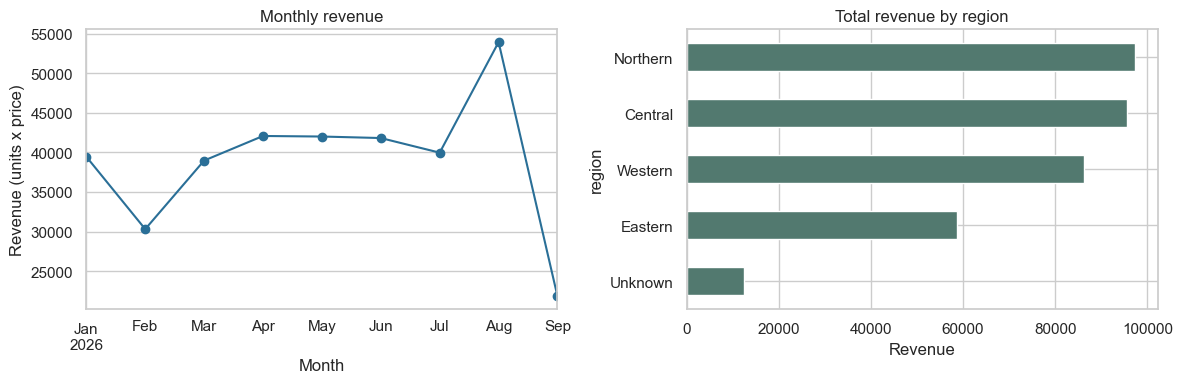

In [18]:
# ---------- Matplotlib ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Line chart: monthly revenue
monthly.plot(ax=axes[0], marker="o", color="#2a6f97")
axes[0].set_title("Monthly revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (units x price)")

# Bar chart: revenue by region
df.groupby("region")["revenue"].sum().sort_values().plot.barh(ax=axes[1], color="#52796f")
axes[1].set_title("Total revenue by region")
axes[1].set_xlabel("Revenue")

plt.tight_layout()
plt.show()

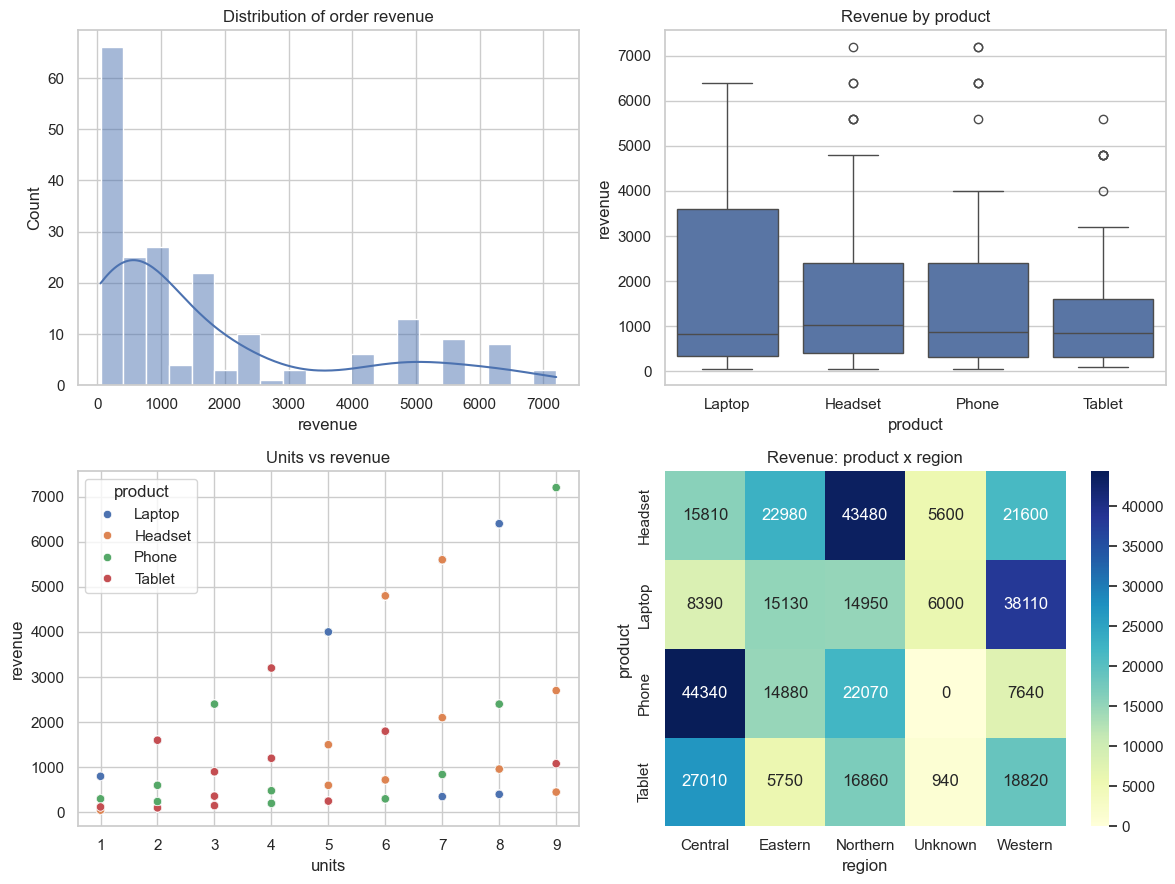

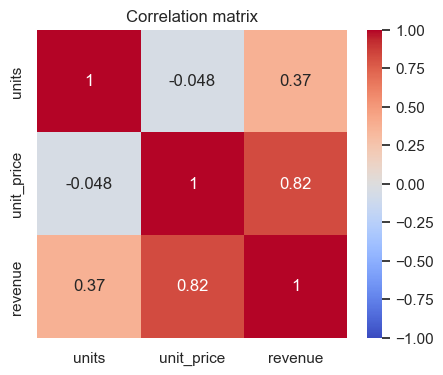

In [19]:
# ---------- Seaborn ----------
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(df["revenue"], bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of order revenue")

sns.boxplot(data=df, x="product", y="revenue", ax=axes[0, 1])
axes[0, 1].set_title("Revenue by product")

sns.scatterplot(data=df, x="units", y="revenue", hue="product", ax=axes[1, 0])
axes[1, 0].set_title("Units vs revenue")

sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[1, 1])
axes[1, 1].set_title("Revenue: product x region")

plt.tight_layout()
plt.show()

# Correlation heatmap of numeric columns
plt.figure(figsize=(5, 4))
sns.heatmap(df[["units", "unit_price", "revenue"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

### Practice — Topic 4
1. NumPy: normalise an array to the 0–1 range using vectorised maths.
2. Pandas: find the best-selling product in each region.
3. Seaborn: draw a `countplot` of orders per product.

[0.         0.33333333 0.16666667 1.         0.83333333]
      region  product  revenue
2    Central    Phone  44340.0
8   Northern  Headset  43480.0
16   Western   Laptop  38110.0
4    Eastern  Headset  22980.0
13   Unknown   Laptop   6000.0


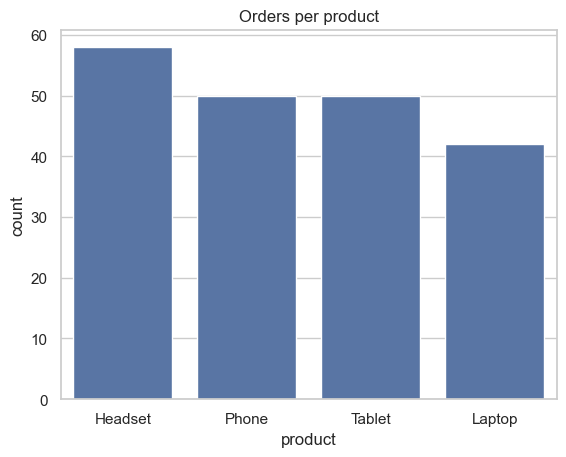

In [20]:
# 1. Min-max normalisation
x = np.array([10, 20, 15, 40, 35])
print((x - x.min()) / (x.max() - x.min()))

# 2. Best product per region (by revenue)
best = (df.groupby(["region", "product"])["revenue"].sum()
          .reset_index()
          .sort_values("revenue", ascending=False)
          .drop_duplicates("region"))
print(best)

# 3. Countplot
sns.countplot(data=df, x="product", order=df["product"].value_counts().index)
plt.title("Orders per product")
plt.show()

# Topic 5 · Introduction to Machine Learning with Python
Machine learning lets a program **learn patterns from data** instead of following hand-written rules.

## 5.1 Basics of scikit-learn
scikit-learn gives every model the **same interface**:

```
model = SomeModel(hyper_parameters)
model.fit(X_train, y_train)        # learn
y_pred = model.predict(X_test)     # predict
model.score(X_test, y_test)        # evaluate
```
Standard workflow: **load data → split train/test → (scale) → fit → predict → evaluate**.

* **Features (X)** – the inputs. **Target (y)** – what we want to predict.
* We **split** data so we can test on examples the model has never seen (guards against *overfitting*).
* A **Pipeline** chains preprocessing and a model into one object.

In [21]:
from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
print(X.head())
print("Classes:", list(iris.target_names))
print("Shape:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Shape: (150, 4)
Train: (112, 4) | Test: (38, 4)


## 5.2 Supervised vs unsupervised learning
| | **Supervised** | **Unsupervised** |
|---|---|---|
| Data | features **+ labels** (known answers) | features only |
| Goal | predict the label | discover structure |
| Tasks | **Classification** (category), **Regression** (number) | **Clustering**, dimensionality reduction |
| Examples | spam detection, house-price prediction | customer segmentation, topic discovery |
| Algorithms | Linear/Logistic Regression, Decision Trees, KNN | K-Means, PCA |

### Supervised — classification (predict a category)

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=200)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=3, random_state=42),
    "KNN (k=5)":           make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    cv = cross_val_score(model, X, y, cv=5).mean()
    print(f"{name:<20} test accuracy = {acc:.3f} | 5-fold CV = {cv:.3f}")

Logistic Regression  test accuracy = 0.921 | 5-fold CV = 0.960
Decision Tree        test accuracy = 0.895 | 5-fold CV = 0.973
KNN (k=5)            test accuracy = 0.921 | 5-fold CV = 0.960


### Supervised — regression (predict a number)

R^2  : 0.485
RMSE : 53.37


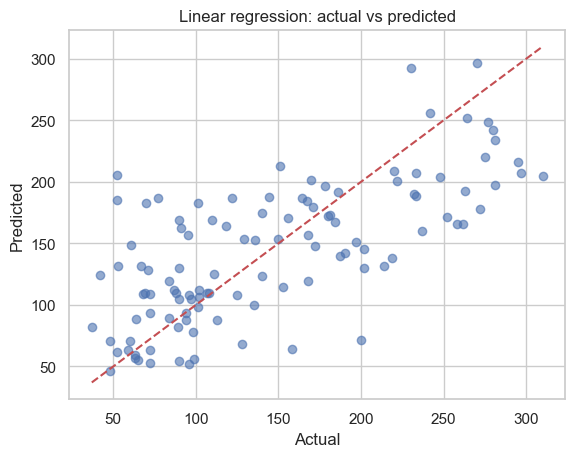

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

diab = load_diabetes(as_frame=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    diab.data, diab.target, test_size=0.25, random_state=42)

reg = LinearRegression().fit(Xd_train, yd_train)
pred = reg.predict(Xd_test)
print("R^2  :", round(r2_score(yd_test, pred), 3))
print("RMSE :", round(mean_squared_error(yd_test, pred) ** 0.5, 2))

plt.scatter(yd_test, pred, alpha=0.6)
plt.plot([yd_test.min(), yd_test.max()], [yd_test.min(), yd_test.max()], "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Linear regression: actual vs predicted")
plt.show()

### Unsupervised — clustering and PCA (no labels used)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

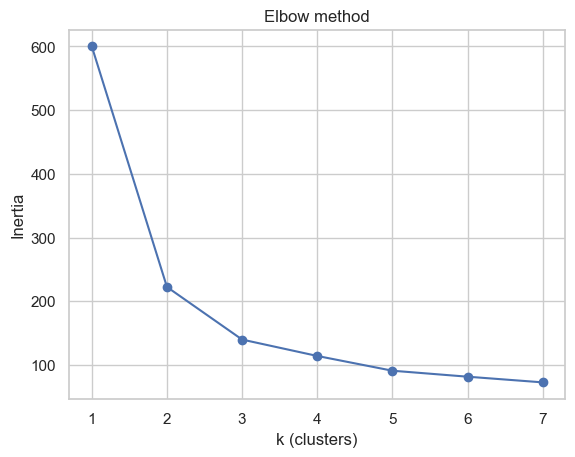

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


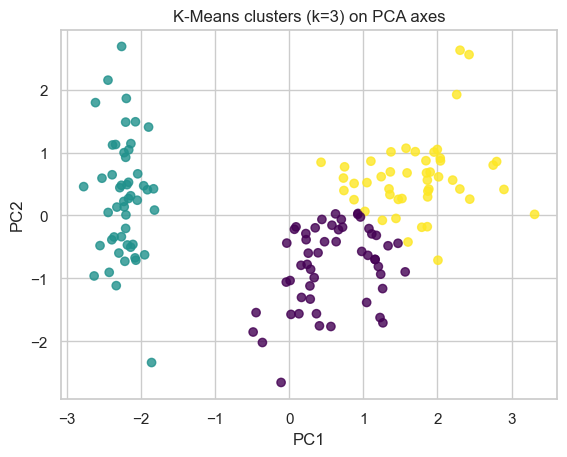

In [24]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

X_scaled = StandardScaler().fit_transform(X)       # note: y is NOT used

# Elbow method: choose k
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_ for k in range(1, 8)]
plt.plot(range(1, 8), inertia, marker="o")
plt.xlabel("k (clusters)"); plt.ylabel("Inertia"); plt.title("Elbow method")
plt.show()

km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_scaled)

# PCA squeezes 4 features into 2 so we can plot
pcs = PCA(n_components=2).fit_transform(X_scaled)
plt.scatter(pcs[:, 0], pcs[:, 1], c=km.labels_, cmap="viridis", alpha=0.8)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("K-Means clusters (k=3) on PCA axes")
plt.show()

## 5.3 Implementing a simple machine learning model — end to end
We'll predict whether a customer **churns** (leaves). Steps: build data → explore → split → train → evaluate → interpret → predict for a new customer.

*(Synthetic data keeps the notebook self-contained; swap in your own CSV with `pd.read_csv(...)` for the coursework.)*

In [25]:
from sklearn.ensemble import RandomForestClassifier

# 1. Build a dataset
rng = np.random.default_rng(0)
n = 800
churn = pd.DataFrame({
    "tenure_months":   rng.integers(1, 72, n),
    "monthly_charge":  rng.normal(60, 20, n).round(2),
    "support_calls":   rng.poisson(2, n),
})
# Churn is more likely with short tenure, high charges and many calls
risk = (-0.04 * churn["tenure_months"] + 0.02 * churn["monthly_charge"] + 0.35 * churn["support_calls"])
churn["churned"] = (risk + rng.normal(0, 0.5, n) > 0.6).astype(int)

print(churn["churned"].value_counts(normalize=True).round(3))
churn.head()

churned
0    0.569
1    0.431
Name: proportion, dtype: float64


,tenure_months,monthly_charge,support_calls,churned
0,61,55.85,2,0
1,46,48.38,0,0
2,37,70.63,2,1
3,20,61.78,4,1
4,22,91.88,2,1


Accuracy: 0.84
              precision    recall  f1-score   support

      Stayed       0.84      0.89      0.86       114
     Churned       0.84      0.78      0.81        86

    accuracy                           0.84       200
   macro avg       0.84      0.83      0.84       200
weighted avg       0.84      0.84      0.84       200



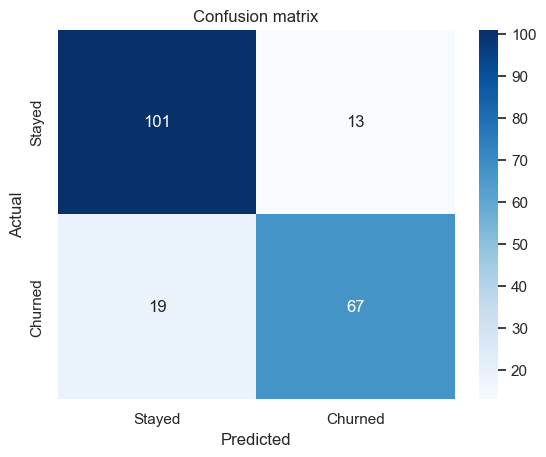

In [26]:
# 2. Split
features = ["tenure_months", "monthly_charge", "support_calls"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    churn[features], churn["churned"], test_size=0.25, random_state=1, stratify=churn["churned"])

# 3. Train
clf = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=1)
clf.fit(Xc_train, yc_train)

# 4. Evaluate
pred = clf.predict(Xc_test)
print("Accuracy:", round(accuracy_score(yc_test, pred), 3))
print(classification_report(yc_test, pred, target_names=["Stayed", "Churned"]))

cm = confusion_matrix(yc_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.show()

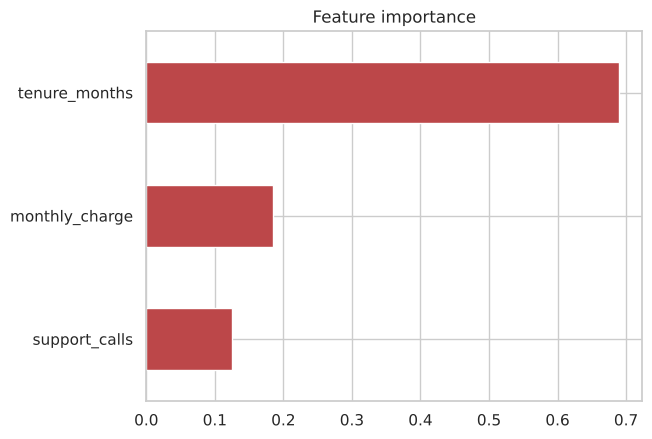

Probability this customer churns: 99.2%


In [29]:
# 5. Interpret: which features matter most?
imp = pd.Series(clf.feature_importances_, index=features).sort_values()
imp.plot.barh(color="#bc4749")
plt.title("Feature importance"); plt.show()

# 6. Predict for a new customer
new_customer = pd.DataFrame([{"tenure_months": 3, "monthly_charge": 85.0, "support_calls": 6}])
prob = clf.predict_proba(new_customer)[0, 1]
print(f"Probability this customer churns: {prob:.1%}")

**Reading the metrics**
* **Accuracy** – share of correct predictions (misleading if classes are imbalanced).
* **Precision** – of those predicted *churn*, how many really churned.
* **Recall** – of the real churners, how many we caught.
* **F1** – balance of precision and recall.
* **Overfitting** – great on training data, poor on test data. Detect it by comparing the two scores; fix it with simpler models, more data, or cross-validation.

### Practice — Topic 5
Compare the training accuracy and test accuracy of a `DecisionTreeClassifier` for `max_depth` from 1 to 10. When does it start to overfit?

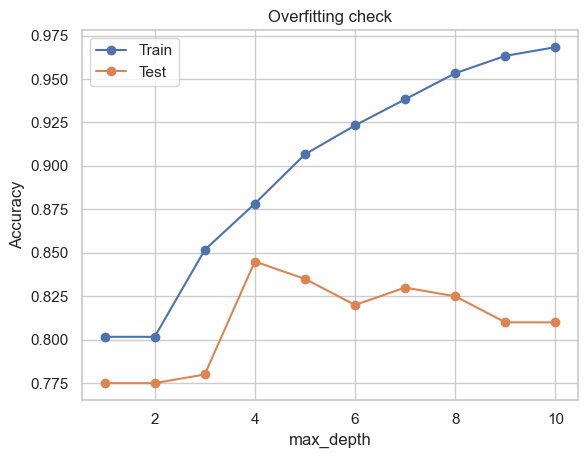

In [27]:
depths = range(1, 11)
train_acc, test_acc = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=1).fit(Xc_train, yc_train)
    train_acc.append(tree.score(Xc_train, yc_train))
    test_acc.append(tree.score(Xc_test, yc_test))

plt.plot(depths, train_acc, marker="o", label="Train")
plt.plot(depths, test_acc, marker="o", label="Test")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Overfitting check")
plt.show()

# Topic 6 · Debugging and Code Optimization
Writing code is only half the job — finding faults, making code clean and fast, and tracking changes are what make it professional.

## 6.1 Common Python errors and debugging techniques
| Error | Typical cause |
|-------|---------------|
| `SyntaxError` | missing colon/bracket, bad indentation |
| `NameError` | variable used before it's defined / typo |
| `TypeError` | wrong type (e.g. `"5" + 5`) |
| `ValueError` | right type, wrong value (`int("abc")`) |
| `IndexError` / `KeyError` | list index / dictionary key doesn't exist |
| `AttributeError` | object has no such attribute/method |
| `FileNotFoundError` | wrong path |
| `ZeroDivisionError` | dividing by zero |

**Techniques:** read the **traceback** from the bottom up · `print()` / f-string checks · **`assert`** statements · the **`logging`** module · the debugger (`pdb`, `%debug` in Jupyter) · isolate the bug with a minimal example · write **unit tests**.

In [28]:
# Triggering each common error on purpose, and catching it, to recognise them
tests = {
    "NameError":       lambda: undefined_variable,
    "TypeError":       lambda: "5" + 5,
    "ValueError":      lambda: int("abc"),
    "IndexError":      lambda: [1, 2, 3][10],
    "KeyError":        lambda: {"a": 1}["b"],
    "AttributeError":  lambda: (5).append(1),
    "ZeroDivisionError": lambda: 1 / 0,
}
for name, fn in tests.items():
    try:
        fn()
    except Exception as e:
        print(f"{name:<18} -> {type(e).__name__}: {e}")

NameError          -> NameError: name 'undefined_variable' is not defined
TypeError          -> TypeError: can only concatenate str (not "int") to str
ValueError         -> ValueError: invalid literal for int() with base 10: 'abc'
IndexError         -> IndexError: list index out of range
KeyError           -> KeyError: 'b'
AttributeError     -> AttributeError: 'int' object has no attribute 'append'
ZeroDivisionError  -> ZeroDivisionError: division by zero


In [29]:
# A buggy function and how we debug it
def average_buggy(values):
    total = 0
    for v in values:
        total += v
    return total / len(values) + 1        # BUG: stray "+ 1"

# Technique 1: assert with a known answer exposes the bug
try:
    assert average_buggy([2, 4, 6]) == 4, "expected 4"
except AssertionError as e:
    print("Test failed:", e, "-> got", average_buggy([2, 4, 6]))

# Technique 2: logging (better than print - has levels, timestamps)
import logging
logging.basicConfig(level=logging.DEBUG, format="%(levelname)s: %(message)s", force=True)

def average_fixed(values):
    logging.debug("Input values: %s", values)
    if not values:
        logging.warning("Empty list received")
        return 0
    result = sum(values) / len(values)
    logging.debug("Computed average: %s", result)
    return result

assert average_fixed([2, 4, 6]) == 4
average_fixed([])

DEBUG: Input values: [2, 4, 6]
DEBUG: Computed average: 4.0
DEBUG: Input values: []


Test failed: expected 4 -> got 5.0


0

Test failed: expected 4 -> got 5.0


0

## 6.2 Best coding practices for efficiency and readability
**Readability (PEP 8)**
* descriptive names (`monthly_revenue`, not `mr`); `snake_case` for functions/variables, `CamelCase` for classes
* 4-space indentation, lines ≲ 79 characters
* docstrings and *useful* comments (explain **why**, not what)
* one function = one job; avoid "magic numbers" (use named constants)
* **DRY** – Don't Repeat Yourself

**Efficiency**
* use **vectorised** NumPy/pandas instead of Python loops
* use the right data structure (set/dict lookups are O(1); list lookups are O(n))
* use list comprehensions and generators; avoid building huge intermediate lists
* **measure first** (`%timeit`, `time`, `cProfile`) — don't guess

In [31]:
import time

# --- Readability: before vs after ---
def f(l):                        # unclear
    r = []
    for i in l:
        if i % 2 == 0: r.append(i * i)
    return r

EVEN = 2
def squares_of_even_numbers(numbers):
    """Return the squares of the even numbers in `numbers`."""
    return [n ** 2 for n in numbers if n % EVEN == 0]

print(f(range(10)) == squares_of_even_numbers(range(10)))

# --- Efficiency 1: loop vs vectorised NumPy ---
big = np.arange(2_000_000)

t0 = time.perf_counter()
loop_result = [x * 2 for x in big]
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
vec_result = big * 2
t_vec = time.perf_counter() - t0
print(f"Python loop: {t_loop:.3f}s | NumPy vectorised: {t_vec:.4f}s | ~{t_loop / t_vec:.0f}x faster")

# --- Efficiency 2: membership test in list vs set ---
items_list = list(range(100_000))
items_set = set(items_list)
t0 = time.perf_counter(); [99_999 in items_list for _ in range(200)]; t_list = time.perf_counter() - t0
t0 = time.perf_counter(); [99_999 in items_set for _ in range(200)];  t_set  = time.perf_counter() - t0
print(f"list lookup: {t_list:.4f}s | set lookup: {t_set:.6f}s")

# --- Efficiency 3: generator saves memory ---
import sys
squares_list = [x ** 2 for x in range(1_000_000)]
squares_gen  = (x ** 2 for x in range(1_000_000))
print("list size:", sys.getsizeof(squares_list), "bytes | generator size:", sys.getsizeof(squares_gen), "bytes")

# --- Efficiency 4: caching repeated work (memoisation) ---
from functools import lru_cache

def fib_slow(n): return n if n < 2 else fib_slow(n - 1) + fib_slow(n - 2)

@lru_cache(maxsize=None)
def fib_fast(n): return n if n < 2 else fib_fast(n - 1) + fib_fast(n - 2)

t0 = time.perf_counter(); fib_slow(27); t_slow = time.perf_counter() - t0
t0 = time.perf_counter(); fib_fast(27); t_fast = time.perf_counter() - t0
print(f"fib(27) plain: {t_slow:.3f}s | cached: {t_fast:.6f}s")

True
Python loop: 0.414s | NumPy vectorised: 0.0094s | ~44x faster
list lookup: 0.2351s | set lookup: 0.000156s
list size: 8448728 bytes | generator size: 200 bytes
fib(27) plain: 0.092s | cached: 0.000181s


Python loop: 0.177s | NumPy vectorised: 0.0065s | ~27x faster


list lookup: 0.1521s | set lookup: 0.000175s


list size: 8448728 bytes | generator size: 200 bytes
fib(27) plain: 0.030s | cached: 0.000065s


## 6.3 Unit testing
A **unit test** checks that a small piece of code gives the expected result. Re-running tests after every change catches *regressions* early. Python ships with `unittest`; many people prefer `pytest`.

In [32]:
import unittest

def celsius_to_fahrenheit(c):
    return c * 9 / 5 + 32

class TestConversion(unittest.TestCase):
    def test_freezing(self):
        self.assertEqual(celsius_to_fahrenheit(0), 32)
    def test_boiling(self):
        self.assertEqual(celsius_to_fahrenheit(100), 212)
    def test_negative(self):
        self.assertAlmostEqual(celsius_to_fahrenheit(-40), -40)

suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestConversion)
unittest.TextTestRunner(verbosity=2).run(suite);

test_boiling (__main__.TestConversion.test_boiling) ... ok
test_freezing (__main__.TestConversion.test_freezing) ... ok
test_negative (__main__.TestConversion.test_negative) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.003s

OK


ok


test_freezing (__main__.TestConversion.test_freezing) ... 

ok


test_negative (__main__.TestConversion.test_negative) ... 

ok


----------------------------------------------------------------------
Ran 3 tests in 0.002s

OK


## 6.4 Version control with Git and GitHub
**Git** records snapshots (*commits*) of your project so you can see history, undo mistakes and work in parallel on *branches*. **GitHub** hosts Git repositories online for backup and collaboration (pull requests, issues, code review).

**Core workflow**
```
git init                      # start tracking a folder
git status                    # what changed?
git add <file>                # stage changes
git commit -m "message"       # save a snapshot
git branch feature-x          # create a branch
git switch feature-x          # move to it
git merge feature-x           # combine it back
git log --oneline             # view history
git remote add origin <url>   # link to GitHub
git push -u origin main       # upload
git pull                      # download others' changes
git clone <url>               # copy a repo
```
**Good habits:** small, frequent commits · meaningful messages · never commit passwords/API keys · use a `.gitignore` for data files, caches and virtual environments.

### Practice — Topic 6
1. Find and fix the bug(s) in the function below, then write two `assert` tests for it.
2. Time a loop vs a vectorised version of the same calculation.

In [36]:
# Buggy version: should return the largest value in a list
def largest_buggy(values):
    biggest = 0                 # BUG: fails for all-negative lists
    for v in values:
        if v > biggest:
            biggest = v
    return biggest

print("buggy:", largest_buggy([-5, -2, -9]))      # wrong (0)

def largest(values):
    if not values:
        raise ValueError("values must not be empty")
    biggest = values[0]         # FIX: start from the first element
    for v in values[1:]:
        if v > biggest:
            biggest = v
    return biggest

assert largest([-5, -2, -9]) == -2
assert largest([3, 8, 1]) == 8
print("fixed: all tests passed")

buggy: 0
fixed: all tests passed


# Summary
| Topic | You should be able to... |
|-------|------------------------------|
| **1. Control flow & functions** | branch with `if/elif/else`, loop with `for`/`while`, write reusable functions, use recursion and lambdas |
| **2. Data structures & files** | pick between list/tuple/set/dict, read & write text/CSV/JSON, handle errors with `try/except/finally` |
| **3. OOP** | design classes, use inheritance/encapsulation/polymorphism, create and import modules & packages |
| **4. DS libraries** | vectorise with NumPy, clean/group/merge with Pandas, plot with Matplotlib & Seaborn |
| **5. Machine learning** | split data, fit/predict/evaluate with scikit-learn, tell supervised from unsupervised, spot overfitting |
| **6. Debugging & optimisation** | read tracebacks, test with `assert`/`unittest`, log, follow PEP 8, time code, use Git branches & commits |